\begin{equation*}
Input: X+ϵ → ℜ^{1x8};ϵ \sim η(\mu,σ)
\end{equation*}

\begin{equation*}
Output: Y=X→ ℜ^{1x8}
\end{equation*}

\begin{equation*}
Flujos: F→ ℜ^{1x59}
\end{equation*}

\begin{equation*}
Costos: C→ ℜ^{1x59}
\end{equation*}

\begin{equation*}
 F_{d} \epsilon F → ℜ^{1x8}
\end{equation*}
\begin{equation*}
 F_{w} \epsilon F → ℜ^{1x1}
\end{equation*}
\begin{equation*}
 C_{d} \epsilon C → ℜ^{1x8}
\end{equation*}
\begin{equation*}
 C_{w} \epsilon C → ℜ^{1x1}
\end{equation*}
\begin{equation*}
 loss: 1-\frac{1}{N}∑exp(-\frac{(F_{d}C_{d}+F_{w}C_{w}-YC_{d})^{2}}{2σ^{2}})
\end{equation*}
variables que conozco, X, Y y C lo demás se estima por la red

Cd tiene magnitudes de 1000000, Cw de 5000

In [1]:
!pip uninstall -y tensorflow tf-keras

# Install TensorFlow 2.16
!pip install tensorflow==2.15.1

# Restart the runtime (manually or using the following command)
#import os
#os._exit(00)


Found existing installation: tensorflow 2.17.0
Uninstalling tensorflow-2.17.0:
  Successfully uninstalled tensorflow-2.17.0
Found existing installation: tf_keras 2.17.0
Uninstalling tf_keras-2.17.0:
  Successfully uninstalled tf_keras-2.17.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 475.2/475.2 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 59.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.0/442.0 kB 28.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.9/77.9 kB 8.3 MB/s eta 0:00:00
  Attempting uninstall: wrapt
    Found existing installation: wrapt 1.16.0
    Uninstalling wrapt-1.16.0:
      Successfully uninstalled wrapt-1.16.0
  Attempting uninstall: ml-dtypes
    Found existing installation: ml-dtypes 0.4.1
    Uninstalling ml-dtypes-0.4.1:
      Successfully u

In [2]:
from google.colab import drive
from tensorflow.python.ops.nn_ops import softmax
from keras import backend as k
import numpy as np
from matplotlib.gridspec import GridSpec
from IPython import display
from scipy.optimize import linprog
from sklearn.metrics import mean_squared_error,mean_absolute_error,mean_absolute_percentage_error
import numpy as np
import matplotlib. pyplot as plt
from keras.layers import Activation,Dense,Input,BatchNormalization,Dropout,Conv1D,Flatten,MaxPool1D,Dot,Reshape,Conv2D,Concatenate,ReLU,Lambda,MaxPooling2D,Normalization,Reshape
import cvxpy as cp
import tensorflow as tf
from keras import Model
from IPython import display
from tensorflow.keras import layers
from tensorflow.keras import regularizers
import warnings
import os
import pandas as pd
import pandas as pd
from IPython import display
path='/content/drive/Shareddrives/red_gas_col/Data/'
from keras.models import Sequential
mse=mean_squared_error
mae=mean_absolute_error
mape=mean_absolute_percentage_error
!pip install spektral
!pip install visualkeras
warnings.filterwarnings("ignore")
#drive.mount('/content/drive')
from scipy.sparse import coo_matrix, eye, hstack
from tensorflow.keras.callbacks import Callback
!pip -q install torch_geometric
import torch
from torch_geometric.utils import to_dense_adj
from spektral.layers import GCNConv

!pip install spektral
!pip install visualkeras
from google.colab import drive
drive.mount('/content/drive')
import tensorflow as tf
import numpy as np




   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 993.7/993.7 kB 53.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 59.2 MB/s eta 0:00:00
Mounted at /content/drive


In [3]:
def model_op(loss: str ='huber') -> Model:
    """
    Create a Keras model with a set of dense layers and custom regularization.

    Returns:
        A Keras Model object.
    """
    input_tensor = Input(shape=(2,))
    regularization_strength = 1e-1
    learning_rate = 1e-3
    layer = input_tensor
    for i in range(1, 5):
        layer = Dense(
            32,
            activation='selu',
            kernel_regularizer=regularizers.L1L2(
                l1=regularization_strength,
                l2=regularization_strength
            ),
            name=f'Dense_{i}'
        )(layer)

    weights = Dense(
        2,
        activation='selu',
        kernel_regularizer=regularizers.L1L2(
            l1=regularization_strength,
            l2=regularization_strength
        ),
        name='W',
        kernel_constraint=tf.keras.constraints.MaxNorm(1)
    )(layer)

    output_tensor = tf.reduce_sum(tf.multiply(weights, input_tensor), axis=-1)
    output_tensor = Reshape((1,))(output_tensor)
    model = Model(inputs=input_tensor, outputs=output_tensor)
    model.compile(loss = loss, optimizer=tf.keras.optimizers.Adam(learning_rate))
    return model

In [4]:
model_op().summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 2)]                  0         []                            
                                                                                                  
 Dense_1 (Dense)             (None, 32)                   96        ['input_1[0][0]']             
                                                                                                  
 Dense_2 (Dense)             (None, 32)                   1056      ['Dense_1[0][0]']             
                                                                                                  
 Dense_3 (Dense)             (None, 32)                   1056      ['Dense_2[0][0]']             
                                                                                              

# Objetivo 1

In [5]:

def GenW(Data_inf,Data_W,Data_T,Data_C,Data_Dc,Data_sto):
    N = len(Data_inf)
    W = len(Data_W)
    wells = coo_matrix((np.ones(W, ), (Data_W['node'] - 1, np.arange(W))), shape=(N, W))
    P = len(Data_T)
    data = np.concatenate((-1.0 * np.ones(P), np.ones(P)))
    row = pd.concat((Data_T['fnode'] - 1, Data_T['tnode'] - 1))
    col = np.concatenate(2 * [np.arange(P)])

    pipes = coo_matrix((data, (row, col)), shape=(N, P))

    C = len(Data_C)
    data = np.concatenate((-1.0 * np.ones(C), np.ones(C)))
    row = pd.concat((Data_C['fnode'] - 1, Data_C['tnode'] - 1))
    col = np.concatenate(2 * [np.arange(C)])
    comps = coo_matrix((data, (row, col)), shape=(N, C))
    users=hstack(len(Data_Dc.T) * [eye(N)])
    S = len(Data_sto)
    sto = coo_matrix((np.ones(S, ), (Data_sto['node'] - 1, np.arange(S))), shape=(N, S))
    sto = hstack([sto, -1.0 * sto])
    w=(hstack((wells, pipes, comps, users, sto))).toarray()
    return w





def split(F_d,F_O):
    y=F_O
    X_train,X_test,y_train, y_test = train_test_split(F_d,y,test_size=0.2)
    return X_train,X_test,y_train, y_test


def flow(C,li,name,e,initializer):
    #D=Dense(1024,activation='selu',kernel_initializer=initializer)(C)
    D=BatchNormalization()(C)
    D=Dense(len(li),name=name,activation=e,kernel_initializer=initializer)(D)

    return D
def pres(C,li,ls,name,initializer):
    D=BatchNormalization()(C)
    D=Dense(len(li),name=name,activation=custom_activation1(li,ls),kernel_initializer=initializer)(C)
    return D

def Flujos(model,X_test):
    model_B = tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('Flujos').output)
    F=model_B.predict(X_test,verbose=False)
    return F

class custom_activation1:
    def __init__(self, lower_bound, upper_bound):
        self.li=tf.cast(lower_bound, tf.float32)
        self.ls=tf.cast(upper_bound, tf.float32)

    def __call__(self, x):
        x=tf.cast(x, tf.float32)
        x=tf.sigmoid(x)*(self.ls-self.li)+self.li
        return x

    def get_config(self):
        return {
            "lower_bound": self.li,
            "upper_bound": self.ls
        }

    @classmethod
    def from_config(cls, config):
        return cls(**config)




class LRReducer(Callback):
    def __init__(self, epoch_threshold):
        super(LRReducer, self).__init__()
        self.epoch_threshold = epoch_threshold

    def on_epoch_begin(self, epoch, logs=None):
        if epoch in self.epoch_threshold:
            lr = float(self.model.optimizer.lr)
            new_lr = lr * 0.1
            self.model.optimizer.lr.assign(new_lr)


import tensorflow as tf

class WellDense(tf.keras.layers.Layer):
    def __init__(self, well=80.0, **kwargs):
        super(WellDense, self).__init__(**kwargs)
        self.well = tf.Variable(initial_value=well, trainable=False, dtype=tf.float32)
    def call(self, inputs):
        x = inputs
        w = tf.reduce_sum(x, axis=1, keepdims=True)
        w = tf.where(w >= self.well, self.well, w)
        return w
    def get_config(self):
        config = super(WellDense, self).get_config()
        config.update({"well": self.well.numpy()})
        return config
    @classmethod
    def from_config(cls, config):
        return cls(**config)


class RestrictedDense(tf.keras.layers.Layer):
    def __init__(self, initializer, well, units, **kwargs):
        super().__init__(**kwargs)
        self.initializer = initializer
        self.units = units
        self.well = tf.constant(well, dtype=tf.float32)


    def call(self, inputs):
        x, In, fw = inputs
        x = tf.where(x <= 0., 0., x)
        x = tf.where(x <= In, x, In)
        mask = tf.where(tf.reduce_sum(In, axis=-1, keepdims=True) <= self.well, 0.0, 1.0)
        x = x * mask
        return x

    def get_config(self):
        config = super().get_config()
        config.update({
            "initializer": tf.keras.initializers.serialize(self.initializer),
            "well": self.well,
            "units": self.units
        })
        return config
    @classmethod
    def from_config(cls, config):
        config['initializer'] = tf.keras.initializers.deserialize(config['initializer'])
        return cls(**config)

class custom_loss2(tf.keras.losses.Loss):
    def __init__(self, Kt, i, j, Bc, ic, jc, find=6, s=0, name="Wey"):
        super().__init__(name=name)
        self.Kt = Kt
        self.i = i
        self.j = j
        self.Bc = Bc
        self.ic = ic
        self.jc = jc
        self.find = find
        self.s = s
        self.lower_bound = tf.constant(1.0, dtype=tf.float32)
        self.upper_bound = tf.constant(Bc, dtype=tf.float32)

    def call(self, y_true, y_pred):
        f = tf.cast(y_pred[:, :self.find], tf.float32)
        P = tf.cast(y_pred[:, self.find:], tf.float32)
        pi = tf.gather(P, self.i, axis=1)
        pj = tf.gather(P, self.j, axis=1)
        loss = tf.keras.losses.huber(f, tf.sign(pi**2-pj**2)*tf.sqrt(self.Kt*tf.abs(pi**2-pj**2)))

        P_ic = tf.gather(P, self.ic, axis=1)
        P_jc = tf.gather(P, self.jc, axis=1)
        h = self.upper_bound + self.lower_bound
        h1 = self.upper_bound - self.lower_bound
        PjPi = tf.math.divide_no_nan(P_jc, P_ic)  # Asumiendo que P_jc y P_ic están definidos
        PjPi_rounded = tf.round(PjPi * 1000) / 1000
        condition = tf.math.logical_and(  PjPi  >= self.lower_bound,PjPi <= self.upper_bound)
        Penalty = tf.reduce_mean(tf.where(condition, 0.0, tf.square((PjPi-0.5*h)/h1)))
        return loss
class custom_loss3(tf.keras.losses.Loss):
    def __init__(self, Kt, i, j, Bc, ic, jc, find=6, s=0, name="Ratio"):
        super().__init__(name=name)
        self.Kt = Kt
        self.i = i
        self.j = j
        self.Bc = Bc
        self.ic = ic
        self.jc = jc
        self.find = find
        self.s = s
        self.lower_bound = tf.constant(1.0, dtype=tf.float32)
        self.upper_bound = tf.constant(Bc, dtype=tf.float32)

    def call(self, y_true, y_pred):
        f = tf.cast(y_pred[:, :self.find], tf.float32)
        P = tf.cast(y_pred[:, self.find:], tf.float32)
        pi = tf.gather(P, self.i, axis=1)
        pj = tf.gather(P, self.j, axis=1)
        loss = tf.keras.losses.huber(f, tf.sign(pi**2-pj**2)*tf.sqrt(self.Kt*tf.abs(pi**2-pj**2)))

        P_ic = tf.gather(P, self.ic, axis=1)
        P_jc = tf.gather(P, self.jc, axis=1)
        h = self.upper_bound + self.lower_bound
        h1 = self.upper_bound - self.lower_bound
        PjPi = tf.math.divide_no_nan(P_jc, P_ic)  # Asumiendo que P_jc y P_ic están definidos
        PjPi_rounded = tf.round(PjPi * 1000) / 1000
        condition = tf.math.logical_and(  PjPi  >= self.lower_bound,PjPi <= self.upper_bound)
        Penalty = tf.reduce_mean(tf.where(condition, 0.0, tf.square((PjPi-0.5*h)/h1)))
        return Penalty

    def get_config(self):
        return {
            "Kt": self.Kt,
            "i": self.i,
            "j": self.j,
            "Bc": self.Bc,
            "ic": self.ic,
            "jc": self.jc,
            "find": self.find,
            "s": self.s
        }
    @classmethod
    def from_config(cls, config):
        return cls(**config)



class FixedWeightsConstraint(tf.keras.constraints.Constraint):
    def __init__(self, w):
        self.w = tf.constant(w.T, dtype=tf.float32)  # Asegúrate de que `w` está en el formato correcto antes de convertirlo a un tensor.

    def __call__(self, weights):
        return self.w

    def get_config(self):
        return {"w": self.w.numpy().tolist()}  # Convierte el tensor a lista para la serialización.

    @classmethod
    def from_config(cls, config):
        return cls(w=config["w"])


def mish(x):
    return x*tf.math.tanh(tf.math.softplus(x))
def swish(x):
    return x*tf.sigmoid(x)


def flow_model(path, fd,U1,U2,a,b,c, s=1,G=1):
    """
    Builds and compiles a TensorFlow Keras model based on data from an Excel file and additional parameters.

    Parameters:
    - path (str): Path to the Excel file containing the model's data.
    - fd (array-like): Additional flow data for the model.
    - seeds (int): Seed for random number generation for reproducibility.
    - s (int): Mode switch for the model configuration.

    Returns:
    - tensorflow.keras.Model: The compiled Keras model.
    """
    Data_inf  =   pd.read_excel(path, sheet_name='node.info')
    Data_D    =   pd.read_excel(path, sheet_name='node.dem')
    Data_Dc   =   pd.read_excel(path, sheet_name='node.demcost')
    Data_W    =   pd.read_excel(path, sheet_name='well')
    Data_T    =   pd.read_excel(path, sheet_name='pipe')
    Data_C    =   pd.read_excel(path, sheet_name='comp')
    Data_sto  =   pd.read_excel(path, sheet_name='sto')
    w = GenW(Data_inf, Data_W, Data_T, Data_C, Data_Dc, Data_sto)
    N = w.shape[0]
    initializer = tf.keras.initializers.GlorotNormal()
    In = Input(shape=(N,))
    N1 = N
    edge_index = torch.tensor([[0, 3, 3, 4, 5, 4, 1, 2],
                           [1, 4, 5, 5, 6, 7, 2, 3]], dtype=torch.long)
    A = to_dense_adj(edge_index)[0].numpy().astype(int)
    N1 = N
    A = tf.convert_to_tensor(A)
    if G==0:
        x=Dense(w.shape[1]*4,'selu',kernel_regularizer=regularizers.L1L2(a,a))(In)
    else:
        x=Reshape((N,1))(In)
        x=GCNConv(w.shape[1]*4,'selu',)([x,A])
        x=Flatten()(x)
        #x=GCNConv(8,'selu')([x,A])
        #x=GCNConv(4,'selu')([x,A])
        #x=GCNConv(2,'selu')([x,A])
        #x=GCNConv(8,Activation='selu')([x,A])
        #x=Dense(w.shape[1]*4,'selu',kernel_regularizer=regularizers.L1L2(a,a))(x)






    #x=Dense(w.shape[1],'selu',kernel_regularizer=regularizers.L1L2(a,a))(x)
    #x=BatchNormalization()(x)
    F = []
    if s == 0:
        Li = np.concatenate((Data_T['Fg_min'].values, [0] * len(Data_C), Data_D['Res'].values * 0.0, Data_D['Ind'].values * 0.0, Data_D['Com'].values * 0.0,
                            Data_D['NGV'].values * 0.0, Data_D['Ref'].values*0.0,
                            Data_D['Pet'].values * 0.0, [0] * len(Data_sto.values) * 2))
        Ls = np.concatenate((Data_T['Fg_max'].values, Data_C['fmaxc'].values, fd, Data_D['Ind'].values * 0.0, Data_D['Com'].values * 0.0, Data_D['NGV'].values * 0.0, Data_D['Ref'].values * 0.0, Data_D['Pet'].values * 0.0,
                            (Data_sto['V0'].values - Data_sto['V_max'].values) * 0.0, (Data_sto['Vmax'].values - Data_sto['V0'].values) * 0.0))
        F = []
        F0 = WellDense(well=Data_W['Imax'].values[0], name='F_0')(In)
        F1 = flow(x,Li,'F_1',custom_activation1(Li,Ls),initializer)
        F = Concatenate(name='F')([F0, F1])  # ,F2,F3])

    elif s == 1:
        fdin = len(Data_W['Imin'].values) + \
            len([0] * len(Data_T)) + len([0] * len(Data_C))
        fdfn = len([0] * len(Data_sto.values) * 2) + \
            len(Data_inf['Pmin'].values)
        F0 = WellDense(well=Data_W['Imax'].values[0], name='F_0')(In)
        Li = Data_T['Fg_min'].values
        Ls = Data_T['Fg_max'].values
        F1 =flow(x,Li,'F_1',custom_activation1(Li,Ls),initializer)

        Li = [0] * len(Data_C)
        Ls = Data_C['fmaxc'].values
        F2 = flow(x,Li,'F_2',custom_activation1(Li,Ls),initializer)
        xt=Dense(N1,'selu',kernel_regularizer=regularizers.L1L2(b,b),kernel_initializer=initializer)(x)
        xt=BatchNormalization()(xt)
        F3 = RestrictedDense(
            initializer=initializer, well=Data_W['Imax'].values[0], name='F_3', units=len(Data_inf))([xt, In, F0])
        Li=np.concatenate((Data_D['Ind'].values*0.0,Data_D['Com'].values*0.0,Data_D['NGV'].values*0.0,Data_D['Ref'].values*0.0,
                        Data_D['Pet'].values*0.0,[0]*len(Data_sto.values)*2))
        Ls=np.concatenate((Data_D['Ind'].values*0.0,Data_D['Com'].values*0.0,Data_D['NGV'].values*0.0,Data_D['Ref'].values*0.0,Data_D['Pet'].values*0.0,
                    (Data_sto['V0'].values-Data_sto['V_max'].values)*0.0,(Data_sto['Vmax'].values-Data_sto['V0'].values)*0.0))
        F4=flow(In,Li,'F_4',custom_activation1(Li,Ls),initializer)
        F = Concatenate(name='F')([F0, F1, F2, F3, F4])

    Out1=Dense(units=w.shape[0],use_bias=False,kernel_constraint=FixedWeightsConstraint(w),name='Bal')(F)

    Kt=tf.constant(Data_T['Kij'].values,dtype=tf.float32)
    i=Data_T['fnode'].values-1
    j=Data_T['tnode'].values-1
    ftin=len(Data_W)
    ftfn=len(Data_T)
    f=F[:,ftin:ftfn+ftin]
    Li=Data_inf['Pmin'].values
    Ls=Data_inf['Pmax'].values
    ib=Data_C['fnode'].values-1
    jb=Data_C['tnode'].values-1


    if G==0:
        x1=Dense(w.shape[1]*4,'selu',kernel_regularizer=regularizers.L1L2(c,c),kernel_initializer=initializer)(In)
        x1=BatchNormalization()(x1)
    else:
        x=Reshape((-1,1))(F1)
        x1=Flatten()(x)
        x1=Dense(w.shape[1]*4,'selu',kernel_regularizer=regularizers.L1L2(c,c),kernel_initializer=initializer)(F1)
        x1=BatchNormalization()(x1)
        #x=GCNConv(8,'selu')([x,A])


        #x1=Dense(w.shape[1]*4,'selu',kernel_regularizer=regularizers.L1L2(c,c),kernel_initializer=initializer)(x1)
        #x1=BatchNormalization()(x1)

    #x1=Dense(N1,'sigmoid',kernel_regularizer=regularizers.L1L2(c,c),kernel_initializer=initializer)(x1)
    #x1=BatchNormalization()(x1)
    P =pres(x1,Li,Ls,'P',initializer)

    Out2 = Concatenate(name='Wey')([f, P])
    Out3 = Concatenate(name='Ratio')([f, P])
    Bc = Data_C['ratio'].values

    model = Model(In, [Out1, Out2,Out3])
    model.compile(loss={'Bal': 'huber', 'Wey': custom_loss2(Kt,i,j,Bc,ib,jb,ftfn),'Ratio': custom_loss3(Kt,i,j,Bc,ib,jb,ftfn)},
                  optimizer=tf.keras.optimizers.Adamax(1e-2), loss_weights=[0.6, 0.1,0.3])
    return model

import time
from keras.callbacks import Callback
class TimeHistory(Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_time_start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.epoch_time_start)
import pandas as pd
import scipy.io as sio
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler,StandardScaler
def EvalBalance(FT,W,X):
    aux1=[]
    aux2=[]
    for i in range(len(FT[0])):
        aux1.append(mape(X[i],FT[0][i]@W.T))
        aux2.append(mape(X[i],FT[1][i]@W.T))
    return[aux1,aux2]
def EvalWeymouth(X,Y):
    aux1=[]
    aux2=[]
    for i in range(len(X[0])):
        aux1.append(mape(X[0][i],Y[0][i]))
        aux2.append(mape(X[1][i],Y[1][i]))
    return[aux1,aux2]
def EvalCost(X,Y):
    aux1=[]
    for i in range(len(X)):
        aux1.append(Y[i] - X[i])
    return aux1
import numpy as np

def dividir_datos(array, indice_test):
    """
    Divide un array en conjuntos de entrenamiento y prueba basado en un índice dado y
    reorganiza el conjunto de entrenamiento a una nueva forma.

    Parámetros:
    - array: Array de entrada con dimensiones (10, 100, 8).
    - indice_test: Índice del sub-array a usar como conjunto de prueba.
a
    Retorna:
    - X_train_reshaped: Array con los datos de entrenamiento reorganizados.
    - X_test: Array con los datos de prueba.
    """
    # Verificar que el índice esté en el rango permitido
    if indice_test < 0 or indice_test >= array.shape[0]:
        raise ValueError("El índice debe estar entre 0 y 9.")

    # Usar el índice para seleccionar el conjunto de prueba y el resto para entrenamiento
    X_test = array[indice_test]
    X_train = np.delete(array, indice_test, axis=0)

    # Cambiar la forma de X_train de (9, 100, 8) a (900, 8)
    X_train_reshaped = np.concatenate(X_train)
    return X_train_reshaped, X_test

In [6]:
def print_model_summary_with_memory(model):
    model.summary()  # Imprimir el resumen estándar

    total_memory = 0
    print("\n{:<20} {:<15}".format("Layer", "Memory (MB)"))
    print("="*35)

    # Iterar sobre cada capa y calcular la memoria usada por los pesos
    for layer in model.layers:
        layer_memory = 0
        for weight in layer.get_weights():
            layer_memory += weight.nbytes/1024  # Convertir bytes a MB
        total_memory += layer_memory
        print("{:<20} {:<15.2f}".format(layer.name, layer_memory))

    print("="*35)
    print(f"Total memory usage: {total_memory:.2f} KB")
lr_reducer = LRReducer(epoch_threshold=[400,500,580])
AJ='S'
s=1
if AJ=='D':
    ajus=[-12.4,-13,-2.8,-1.7,0,4,8,10,10]
elif AJ=='M':
    ajus=[6.5,8.7,10.5,11.9,13.1,14.1,15,15.8,36]
elif AJ=='S':
    ajus=[12.4,13.7,14.8,15.7,16.4,17.2,17.8,18.3,48]

nodos=8
N=20000
path='/content/drive/Shareddrives/red_gas_col/Data/Redes/'
if nodos==18:
    path=path+'ng_caseCol_'+str(nodos)+'.xlsx'
    ajusts=ajus[-1]
else:
    path=path+'ng_case'+str(nodos)+'.xlsx'
    ajusts=ajus[nodos-8]
Data_D=pd.read_excel(path,sheet_name='node.dem')
Data_inf=pd.read_excel(path,sheet_name='node.info')
Data_Dc=pd.read_excel(path,sheet_name='node.demcost')
Data_W=pd.read_excel(path,sheet_name='well')
Data_T=pd.read_excel(path,sheet_name='pipe')
Data_C=pd.read_excel(path,sheet_name='comp')
Data_sto=pd.read_excel(path,sheet_name='sto')
Cost=np.concatenate((Data_W['Cg'].values,Data_T['C_O'].values,Data_C['costc'],Data_Dc['al_Res'].values,
                Data_Dc['al_Ind'].values,Data_Dc['al_Com'].values,Data_Dc['al_NGV'].values,Data_Dc['al_Ref'].values,Data_Dc['al_Pet'].values,
                    Data_sto['C_S+'].values-Data_sto['C_V'].values,-1*(Data_sto['C_S-']-Data_sto['C_V']).values,Data_sto['C_V'].values)).reshape(-1,1)
cost=Cost
w=GenW(Data_inf,Data_W,Data_T,Data_C,Data_Dc,Data_sto)
min=Data_D.values.sum(axis=1).min()
max=Data_D.values.sum(axis=1).max()
X_train,X_test=train_test_split(np.random.uniform(min,max-ajusts,(N,nodos)), shuffle=True,test_size=0.2)
fd = np.array(X_train).max(axis=0)
model=flow_model(path, fd,U1=256,U2=2048,a=1e-4,b=1e-4,c=1e-4, s=s,G=0)
history=model.fit(X_train,X_train,epochs=600,validation_split=0.2,verbose=True,batch_size=256,callbacks=[lr_reducer])
#model.load_weights('/content/drive/MyDrive/red_gas_col/Prueba/Data/M/Modelo2/model2_'+str(nodos)+'.h5')
#history=model.fit(X_train,X_train,epochs=600,validation_split=0.2,verbose=True,batch_size=256,callbacks=[lr_reducer])
#model.summary()
#print_model_summary_with_memory(model)


Epoch 1/600
50/50 [==============================] - 28s 98ms/step - loss: 26.8044 - Bal_loss: 24.0102 - Wey_loss: 98.5496 - Ratio_loss: 8.3436 - val_loss: 15.8362 - val_Bal_loss: 18.4173 - val_Wey_loss: 45.6978 - val_Ratio_loss: 0.5934
Epoch 2/600
50/50 [==============================] - 1s 29ms/step - loss: 8.4638 - Bal_loss: 3.5678 - Wey_loss: 59.5767 - Ratio_loss: 1.0937 - val_loss: 8.3577 - val_Bal_loss: 7.2369 - val_Wey_loss: 37.7158 - val_Ratio_loss: 0.6912
Epoch 3/600
50/50 [==============================] - 1s 29ms/step - loss: 6.8236 - Bal_loss: 2.4206 - Wey_loss: 50.6109 - Ratio_loss: 0.9137 - val_loss: 6.2767 - val_Bal_loss: 3.8324 - val_Wey_loss: 36.8986 - val_Ratio_loss: 0.8390
Epoch 4/600
50/50 [==============================] - 1s 25ms/step - loss: 6.1126 - Bal_loss: 1.9013 - Wey_loss: 46.8868 - Ratio_loss: 0.8251 - val_loss: 6.6735 - val_Bal_loss: 4.1247 - val_Wey_loss: 39.1496 - val_Ratio_loss: 0.8264
Epoch 5/600
50/50 [==============================] - 1s 17ms/step -

KeyboardInterrupt: 

In [ ]:
import numpy as np

# Suponiendo que ya tienes X_train
# X_train = np.random.rand(20000, 8)  # Ejemplo de array si necesitas crearlo

# Parámetros
batch_size = 256

# Seleccionar un batch de datos
batch = X_train[:batch_size]

# Calcular el tamaño en bytes
batch_size_in_bytes = batch.nbytes

# Convertir a megabytes
batch_size_in_megabytes = batch_size_in_bytes / (1024
                                                 )

print(f"Tamaño del batch en memoria: {batch_size_in_megabytes:.2f} MB")


Tamaño del batch en memoria: 16.00 MB


In [ ]:
history.history

{'loss': [26.122148513793945,
  8.361577987670898,
  6.7975897789001465,
  6.3209919929504395,
  6.058823108673096,
  5.797910690307617,
  5.355037212371826,
  5.066648960113525,
  4.847485542297363,
  4.611159801483154,
  4.631995677947998,
  4.272784233093262,
  4.025904655456543,
  3.810774326324463,
  3.6017377376556396,
  3.3721654415130615,
  3.2437474727630615,
  2.9551761150360107,
  2.7384872436523438,
  2.394254207611084,
  2.059988260269165,
  1.857993721961975,
  1.5792704820632935,
  1.3838849067687988,
  1.1278116703033447,
  0.8835844993591309,
  0.6881746649742126,
  0.619716465473175,
  0.5871760249137878,
  0.5366668105125427,
  0.5194116234779358,
  0.44607794284820557,
  0.44983601570129395,
  0.4866331219673157,
  0.4735662043094635,
  0.4377821385860443,
  0.43878859281539917,
  0.4149128794670105,
  0.4082481265068054,
  0.4405575692653656,
  0.429531455039978,
  0.41347548365592957,
  0.4039723575115204,
  0.3989678621292114,
  0.4173840284347534,
  0.4162169992

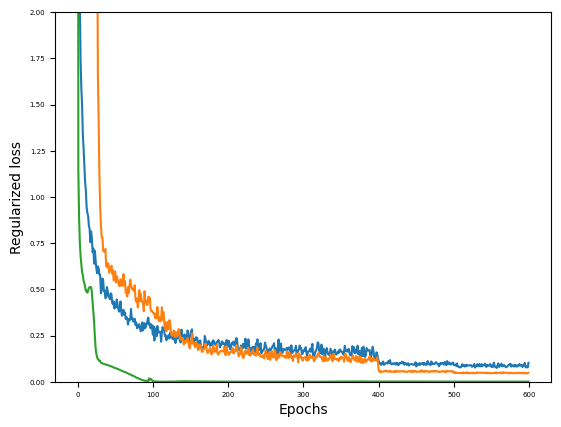

In [ ]:
plt.plot(history.history['Bal_loss'])
plt.plot(history.history['Wey_loss'])
plt.plot(history.history['Ratio_loss'])

plt.ylim([0,2])
plt.xlabel('Epochs')

plt.ylabel('Regularized loss')
plt.tick_params(axis='x', labelsize=5)  # Ajusta el tamaño de las etiquetas del eje x
plt.tick_params(axis='y', labelsize=5)  # Ajusta el tamaño de las etiquetas del eje y
plt.savefig('/content/LossG.pdf',bbox_inches='tight')
plt.show()

2.5 2.7 0.0
2.5 2.7


549

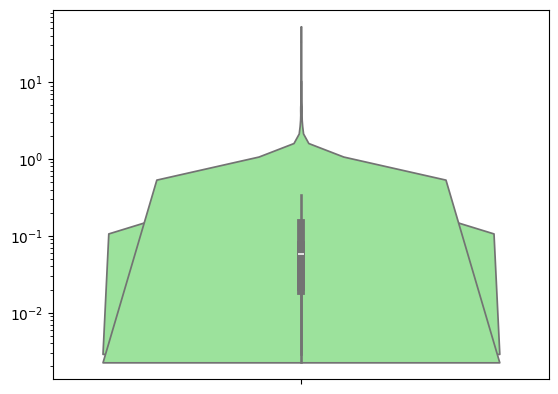

In [ ]:
conta=0
while conta==0:
    AJ='M'
    s=1

    path='/content/drive/MyDrive/red_gas_col/'
    if AJ=='D':
        ajus=[-12.4,-13,-2.8,-1.7,0,4,8,10,10]
    elif AJ=='M':
        ajus=[6.5,8.7,10.5,11.9,13.1,14.1,15,15.8,36]
    elif AJ=='S':
        ajus=[12.4,13.7,14.8,15.7,16.4,17.2,17.8,18.3,48]
    if nodos==18:
        path=path+'ng_caseCol_'+str(nodos)+'.xlsx'
        ajusts=ajus[-1]
    else:
        path=path+'ng_case'+str(nodos)+'.xlsx'
        ajusts=ajus[nodos-8]
    X_test =np.random.uniform(min,max-ajusts,(1000,nodos))
    Wey=[]
    Bal=[]
    Com=[]
    model_A = tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('F').output)
    model_B= tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('P').output)
    Fe=model_A.predict(np.array(X_test),verbose=False)
    Pe=model_B.predict(np.array(X_test),verbose=False)
    i=Data_T['fnode'].values.astype(int)-1
    j=Data_T['tnode'].values.astype(int)-1
    CK=Data_T['Kij'].values.reshape(-1,)
    nod=len(Data_inf)
    Fte=Fe[:,1:1+len(Data_T)]
    Pie=Pe[:,i]
    Pje=Pe[:,j]
    Pte=np.sign(Pie**2-Pje**2)*np.sqrt(CK*np.abs(Pie**2-Pje**2))
    from sklearn.metrics import mean_squared_error,mean_absolute_error,mean_absolute_percentage_error
    mape=mean_absolute_percentage_error
    Wey.append(mape(Fte,Pte))
    Bal.append(mape(X_test,(Fe@w.T)))
    ic = Data_C['fnode'].values.astype(int) - 1
    jc = Data_C['tnode'].values.astype(int) - 1
    Bc = Data_C['ratio'].values
    are = np.round(Pe[:, jc] / Pe[:, ic], 3)
    ind1 = np.unique(np.concatenate((np.where(~(are[:, 0] <= Bc[0]) | ~(are[:, 0] >= 1.0))[
        0], np.where(~(are[:, 1] <= Bc[1]) | ~(are[:, 1] >= 1.0))[0])))
    re1 = np.zeros(X_test.shape[0])
    if len(ind1) != 0:
        re1[ind1] = 0.1
    Com.append(mse(np.zeros(re1.shape),re1))

    Wey=[]
    Bal=[]
    for i in range(len(Fte)):
        Wey.append(mape(Fte[i],Pte[i]))
        Bal.append(mape(X_test[i],(Fe[i]@w.T)))
    Wey=np.array(Wey)
    Bal=np.array(Bal)
    print(Bal[Bal>=1].shape[0]/Bal.shape[0]*100,Wey[Wey>=1].shape[0]/Wey.shape[0]*100,Com[0])
    if (Com[0]==0) and (Bal[Bal>=1].shape[0]/Bal.shape[0]*100<=4.5) and (Wey[Wey>=1].shape[0]/Wey.shape[0]*100<=3.0):
        print(Bal[Bal>=1].shape[0]/Bal.shape[0]*100,Wey[Wey>=1].shape[0]/Wey.shape[0]*100)
        #plt.violinplot(np.array(Wey))

        import seaborn as sns
        #plt.boxplot(np.array(Bal))
        sns.violinplot(data=np.array(Wey), inner='box', cut=0, color='lightgreen')
        sns.violinplot(data=np.array(Bal), inner='box', cut=0, color='lightgreen')
        plt.yscale('log')
        conta=1
a=X_test.sum(axis=1)
a[a<=80].shape[0]

In [ ]:
model=flow_model(path, fd,U1=256,U2=2048,a=1e-4,b=1e-2,c=0, s=1,G=1)
#model.summary()
history=model.fit(X_train,X_train,epochs=600,validation_split=0.2,verbose=True,batch_size=256,callbacks=[lr_reducer])

In [ ]:
X_test =np.random.uniform(min,max-ajusts,(1000,nodos))
Wey=[]
Bal=[]
Com=[]
model_A = tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('F').output)
model_B= tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('P').output)
Fe=model_A.predict(np.array(X_test),verbose=False)
Pe=model_B.predict(np.array(X_test),verbose=False)
i=Data_T['fnode'].values.astype(int)-1
j=Data_T['tnode'].values.astype(int)-1
CK=Data_T['Kij'].values.reshape(-1,)
nod=len(Data_inf)
Fte=Fe[:,1:1+len(Data_T)]
Pie=Pe[:,i]
Pje=Pe[:,j]
Pte=np.sign(Pie**2-Pje**2)*np.sqrt(CK*np.abs(Pie**2-Pje**2))
from sklearn.metrics import mean_squared_error,mean_absolute_error,mean_absolute_percentage_error
mape=mean_absolute_percentage_error
Wey.append(mape(Fte,Pte))
Bal.append(mape(X_test,(Fe@w.T)))
ic = Data_C['fnode'].values.astype(int) - 1
jc = Data_C['tnode'].values.astype(int) - 1
Bc = Data_C['ratio'].values
are = np.round(Pe[:, jc] / Pe[:, ic], 3)
ind1 = np.unique(np.concatenate((np.where(~(are[:, 0] <= Bc[0]) | ~(are[:, 0] >= 1.0))[
    0], np.where(~(are[:, 1] <= Bc[1]) | ~(are[:, 1] >= 1.0))[0])))
re1 = np.zeros(X_test.shape[0])
if len(ind1) != 0:
    re1[ind1] = 0.1
Com.append(mse(np.zeros(re1.shape),re1))
print(Bal,Wey,Com)
Wey=[]
Bal=[]
for i in range(len(Fte)):
    Wey.append(mape(Fte[i],Pte[i]))
    Bal.append(mape(X_test[i],(Fe[i]@w.T)))
plt.boxplot(np.array(Wey))
plt.boxplot(np.array(Bal))
plt.yscale('log')
Wey=np.array(Wey)
Bal=np.array(Bal)
print(mape(X_test,(Fe@w.T)))
Bal[Bal>=1].shape[0]/Bal.shape[0]*100,Wey[Wey>=1].shape[0]/Wey.shape[0]*100

In [ ]:
#model.save_weights('/content/drive/MyDrive/red_gas_col/Prueba/Data/Test/model2_8.h5')
# a=X_test.sum(-1)
# print(a[a<=80].shape[0]/a.shape[0])
# np.save('/content/drive/MyDrive/red_gas_col/Prueba/Data/Test/Red0.npy',X_test)


In [ ]:
!pip install wandb -Uq
import wandb
wandb.login()#47d5f9957387e4a111eaea15937b52e093e1a18d



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.1/267.1 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 2.1 MB/s eta 0:00:00


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter, or press ctrl+c to quit:

 ··········


wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


True

In [ ]:
sweep_config = {
    'method': 'bayes',
    'metric': {
        'name': 'val_loss',
        'goal': 'minimize'
    },
    'parameters': {
        'U1': {
            'values':[64,128,256,512,1024,2048]
        },
        'U2': {
            'values':[64,128,256,512,1024,2048]
        },
        'a': {
             'values': [1e0,0,1e-1,1e-2,1e-3,1e-4]
        },
       'b': {
             'values': [1e0,0,1e-1,1e-2,1e-3,1e-4]
        },
       'c': {
             'values': [1e0,0,1e-1,1e-2,1e-3,1e-4]
        }
    },
    'run_cap':15
}

sweep_id = wandb.sweep(sweep_config, project="Red_18_S")

Create sweep with ID: wnh5dtqm
Sweep URL: https://wandb.ai/daprosero/Red_18_S/sweeps/wnh5dtqm


In [ ]:
from wandb.keras import WandbCallback
class CustomWandbCallback(Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        wandb.log(logs)
def train():
    wandb.init()


    # Accede a los hiperparámetros con wandb.config
    config = wandb.config
    lr_reducer = LRReducer(epoch_threshold=[330,480,570])
    AJ='S'
    if AJ=='D':
        ajus=[-12.4,-13,-2.8,-1.7,0,4,8,8,10]
    elif AJ=='M':
        ajus=[6.5,8.7,10.5,11.9,13.1,14.1,15,15.8,36]
    elif AJ=='S':
        ajus=[12.4,13.7,14.8,15.7,16.4,17.2,17.8,18.3,48]

    nodos=18
    N=20000
    path='/content/drive/Shareddrives/red_gas_col/Prueba/Data/Redes/'
    if nodos==18:
        path=path+'ng_caseCol_'+str(nodos)+'.xlsx'
        ajusts=ajus[-1]
    else:
        path=path+'ng_case'+str(nodos)+'.xlsx'
        ajusts=ajus[nodos-8]
    Data_D=pd.read_excel(path,sheet_name='node.dem')
    min=Data_D.values.sum(axis=1).min()
    max=Data_D.values.sum(axis=1).max()
    X_train,X_test=train_test_split(np.random.uniform(min,max-ajusts,(N,nodos)), shuffle=True,test_size=0.2)
    fd = np.array(X_train).max(axis=0)
    model=flow_model(path, fd,config.U1,config.U2,config.a,config.b,config.c, s=1)
    history=model.fit(X_train,X_train,epochs=600,verbose=False,validation_split=0.2,batch_size=256,callbacks=[CustomWandbCallback(),lr_reducer])
wandb.agent(sweep_id, train)

wandb: Agent Starting Run: ka0kvr1t with config:
wandb: 	U1: 128
wandb: 	U2: 512
wandb: 	a: 0.1
wandb: 	b: 0
wandb: 	c: 0
wandb: Currently logged in as: daprosero. Use `wandb login --relogin` to force relogin


Bal_loss,█▄▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▅▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▅▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▅▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▃▂▂▂▁▂▁▂▂▁▂▂▂▂▂▁▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▅▃▂▂▂▁▁▁▁▂▁▂▂▂▂▂▁▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,1.5703
Wey_loss,2.51468
loss,2.14378
val_Bal_loss,1.3496
val_Wey_loss,10.85042


wandb: Agent Starting Run: v1sh7tt3 with config:
wandb: 	U1: 2048
wandb: 	U2: 256
wandb: 	a: 0.0001
wandb: 	b: 0.0001
wandb: 	c: 0.0001


Bal_loss,█▄▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▅▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▅▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▄▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▃▃▂▂▂▂▂▂▂▁▂▂▂▃▂▂▂▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▅▃▃▂▂▂▂▂▂▁▁▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,1.50615
Wey_loss,4.682
loss,3.1555
val_Bal_loss,1.2657
val_Wey_loss,7.39719


wandb: Agent Starting Run: 2842z7wx with config:
wandb: 	U1: 2048
wandb: 	U2: 256
wandb: 	a: 0.001
wandb: 	b: 0.001
wandb: 	c: 0


Bal_loss,█▅▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▅▄▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▅▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▄▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▄▂▂▁▂▁▂▂▁▂▂▃▂▂▂▂▂▁▂▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▄▃▂▂▂▂▁▂▂▁▁▂▂▂▂▂▂▂▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,1.37305
Wey_loss,3.3103
loss,2.45033
val_Bal_loss,1.13685
val_Wey_loss,10.60019


... (21 outputs left out)

Bal_loss,█▆▅▅▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▅▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▅▄▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▆▅▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▃▂▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▅▄▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,1.3911
Wey_loss,0.37068
loss,0.93126
val_Bal_loss,1.13367
val_Wey_loss,0.19241


wandb: Agent Starting Run: 5hko4p3w with config:
wandb: 	U1: 64
wandb: 	U2: 2048
wandb: 	a: 1
wandb: 	b: 0.01
wandb: 	c: 0.0001


Bal_loss,█▅▄▄▄▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▅▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▅▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▅▅▅▅▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▅▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,1.96973
Wey_loss,0.24924
loss,1.20035
val_Bal_loss,1.79709
val_Wey_loss,0.1639


wandb: Sweep Agent: Waiting for job.
wandb: Sweep Agent: Exiting.


In [ ]:
sweep_config = {
    'method': 'bayes',
    'metric': {
        'name': 'val_loss',
        'goal': 'minimize'
    },
    'parameters': {
        'U1': {
            'values':[64,128,256,512,1024,2048]
        },
        'U2': {
            'values':[64,128,256,512,1024,2048]
        },

        'a': {
             'values': [1e0,0,1e-1,1e-2,1e-3,1e-4]
        },
       'b': {
             'values': [1e0,0,1e-1,1e-2,1e-3,1e-4]
        },
       'c': {
             'values': [1e0,0,1e-1,1e-2,1e-3,1e-4]
        }
    },
    'run_cap':15
}
sweep_id = wandb.sweep(sweep_config, project="Red_13_S")

Create sweep with ID: jqd3dsql
Sweep URL: https://wandb.ai/daprosero/Red_13_S/sweeps/jqd3dsql


In [ ]:
from wandb.keras import WandbCallback
class CustomWandbCallback(Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        wandb.log(logs)
def train():
    wandb.init()


    # Accede a los hiperparámetros con wandb.config
    config = wandb.config
    lr_reducer = LRReducer(epoch_threshold=[330,480,570])
    AJ='S'
    if AJ=='D':
        ajus=[-12.4,-13,-2.8,-1.7,0,4,8,8,10]
    elif AJ=='M':
        ajus=[6.5,8.7,10.5,11.9,13.1,14.1,15,15.8,36]
    elif AJ=='S':
        ajus=[12.4,13.7,14.8,15.7,16.4,17.2,17.8,18.3,48]

    nodos=13
    N=20000
    path='/content/drive/Shareddrives/red_gas_col/Prueba/Data/Redes/'
    if nodos==18:
        path=path+'ng_caseCol_'+str(nodos)+'.xlsx'
        ajusts=ajus[-1]
    else:
        path=path+'ng_case'+str(nodos)+'.xlsx'
        ajusts=ajus[nodos-8]
    Data_D=pd.read_excel(path,sheet_name='node.dem')
    min=Data_D.values.sum(axis=1).min()
    max=Data_D.values.sum(axis=1).max()
    X_train,X_test=train_test_split(np.random.uniform(min,max-ajusts,(N,nodos)), shuffle=True,test_size=0.2)
    fd = np.array(X_train).max(axis=0)
    model=flow_model(path, fd,config.U1,config.U2,config.a,config.b,config.c, s=1)
    history=model.fit(X_train,X_train,epochs=600,verbose=False,validation_split=0.2,batch_size=256,callbacks=[CustomWandbCallback(),lr_reducer])
wandb.agent(sweep_id, train)

wandb: Agent Starting Run: x0slxgqb with config:
wandb: 	U1: 512
wandb: 	U2: 256
wandb: 	a: 1
wandb: 	b: 0.001
wandb: 	c: 0


Bal_loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▆▄▃▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▄▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▆▄▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▄▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,0.13115
Wey_loss,0.17028
loss,0.17098
val_Bal_loss,0.09992
val_Wey_loss,0.18209


wandb: Agent Starting Run: 2zl2f9na with config:
wandb: 	U1: 128
wandb: 	U2: 1024
wandb: 	a: 0.01
wandb: 	b: 1
wandb: 	c: 1


Bal_loss,█▅▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▆▅▅▄▄▄▄▄▄▄▄▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▄▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▅▃▃▂▃▃▃▂▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▄▄▄▃▃▃▃▃▃▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▄▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,0.15144
Wey_loss,0.34023
loss,0.47355
val_Bal_loss,0.11181
val_Wey_loss,0.33096


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: mhzpwa4h with config:
wandb: 	U1: 2048
wandb: 	U2: 256
wandb: 	a: 0.01
wandb: 	b: 0.1
wandb: 	c: 1


Bal_loss,█▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▆▅▄▄▄▄▄▄▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▅▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▆▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▄▃▃▃▃▃▃▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▅▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,0.12079
Wey_loss,0.31066
loss,0.38332
val_Bal_loss,0.0918
val_Wey_loss,0.3072


... (17 outputs left out)

Bal_loss,█▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▆▅▄▄▄▄▄▄▄▄▃▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▄▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▄▃▃▂▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▄▃▃▃▃▃▃▃▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▄▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,0.11037
Wey_loss,0.35722
loss,0.45587
val_Bal_loss,0.08991
val_Wey_loss,0.3526


wandb: Agent Starting Run: g0fue821 with config:
wandb: 	U1: 64
wandb: 	U2: 1024
wandb: 	a: 0.0001
wandb: 	b: 0.0001
wandb: 	c: 0


Bal_loss,█▆▄▃▃▃▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▆▅▅▄▄▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▆▅▄▄▄▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▅▄▃▃▃▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▅▄▄▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▅▅▄▄▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,0.06732
Wey_loss,0.19778
loss,0.14056
val_Bal_loss,0.03633
val_Wey_loss,0.17204


wandb: Agent Starting Run: pa6sor76 with config:
wandb: 	U1: 256
wandb: 	U2: 2048
wandb: 	a: 0.0001
wandb: 	b: 0.001
wandb: 	c: 1
